Overall Company Attrition Rate: 16.12%
Attrition Rate (%) by OverTime & Job Satisfaction:
JobSatisfaction      1      2      3      4
OverTime                                   
No               17.56   9.48   9.97   6.94
Yes              35.71  37.68  33.88  21.13

Employee Profile Comparison:
           mean_income  median_income   mean_age  mean_years_at_company
Attrition                                                              
No         6832.739659         5204.0  37.561233               7.369019
Yes        4787.092827         3202.0  33.607595               5.130802


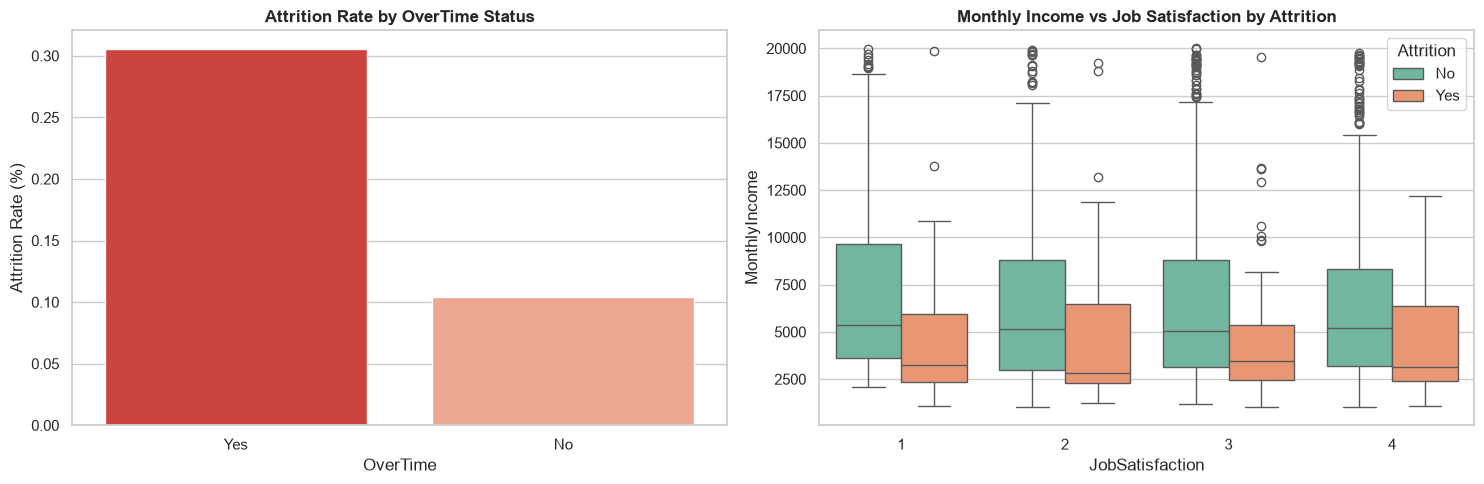

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


df_hr = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')


df_hr['attrition_num'] = np.where(df_hr['Attrition'] == 'Yes', 1, 0)


constant_cols = [col for col in df_hr.columns if df_hr[col].nunique() == 1]
df_hr = df_hr.drop(columns=constant_cols)


overall_attrition_rate = df_hr['attrition_num'].mean() * 100
print(f"Overall Company Attrition Rate: {overall_attrition_rate:.2f}%")


attrition_matrix = df_hr.groupby(['OverTime', 'JobSatisfaction'])['attrition_num'].mean().unstack() * 100

print("Attrition Rate (%) by OverTime & Job Satisfaction:")
print(attrition_matrix.round(2))


attrition_profile = df_hr.groupby('Attrition').agg(
    mean_income=('MonthlyIncome', 'mean'),
    median_income=('MonthlyIncome', 'median'),
    mean_age=('Age', 'mean'),
    mean_years_at_company=('YearsAtCompany', 'mean')
)

print("\nEmployee Profile Comparison:")
print(attrition_profile)


sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))


sns.barplot(
    ax=axes[0], 
    data=df_hr, 
    x='OverTime', 
    y='attrition_num', 
    hue='OverTime', 
    palette='Reds_r', 
    errorbar=None, 
    legend=False
)
axes[0].set_title('Attrition Rate by OverTime Status', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Attrition Rate (%)')


sns.boxplot(
    ax=axes[1], 
    data=df_hr, 
    x='JobSatisfaction', 
    y='MonthlyIncome', 
    hue='Attrition', 
    palette='Set2'
)
axes[1].set_title('Monthly Income vs Job Satisfaction by Attrition', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()